In [20]:

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
     

In [21]:
df= pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\test\customer-segmentation-assignment (1).csv')

In [22]:
df.head()

,Customer_ID,Age,Annual_Income_INR,Monthly_Spend_INR,Monthly_Visits,Orders_Per_Month,Discount_Purchase_Ratio,Avg_Session_Minutes,Returns_Per_Year,Preferred_Category,Primary_Channel
0,CUST00001,42,88237,7371,6,6,0.123,17.5,1,Beauty,Website
1,CUST00002,37,64310,4295,8,2,0.409,14.7,2,Fashion,App
2,CUST00003,63,97564,6189,1,3,0.270,9.5,1,Home,App
3,CUST00004,44,120787,7524,7,6,0.242,19.8,1,Home,Website
4,CUST00005,43,125044,4260,3,3,0.349,7.9,0,Electronics,App


In [23]:

# Check the number of rows and columns
print(df.shape)

# Check for missing values
print(df.isnull().sum().sum())

# Check for duplicate rows
print(df.duplicated().sum())

(5000, 11)
0
0


In [24]:
# Remove Customer_ID and non-numeric columns because they are not suitable for clustering
X = df.drop(columns=['Customer_ID', 'Preferred_Category', 'Primary_Channel'])

print(X.head())


   Age  Annual_Income_INR  Monthly_Spend_INR  Monthly_Visits  \
0   42              88237               7371               6   
1   37              64310               4295               8   
2   63              97564               6189               1   
3   44             120787               7524               7   
4   43             125044               4260               3   

   Orders_Per_Month  Discount_Purchase_Ratio  Avg_Session_Minutes  \
0                 6                    0.123                 17.5   
1                 2                    0.409                 14.7   
2                 3                    0.270                  9.5   
3                 6                    0.242                 19.8   
4                 3                    0.349                  7.9   

   Returns_Per_Year Preferred_Category Primary_Channel  
0                 1             Beauty         Website  
1                 2            Fashion             App  
2                 1          

In [ ]:
# Create the scaler
scaler = StandardScaler()

# Standardize numeric features only
X_numeric = X.select_dtypes(include='number')
X_scaled = scaler.fit_transform(X_numeric)

print("Data standardized successfully")


In [27]:
# Create the Hierarchical Clustering model
hc = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

# Fit the model and assign cluster labels
df['Hierarchical_Cluster'] = hc.fit_predict(X_scaled)

# Display the cluster assigned to each customer
print(df[['Customer_ID', 'Hierarchical_Cluster']].head(10))

  Customer_ID  Hierarchical_Cluster
0   CUST00001                     3
1   CUST00002                     0
2   CUST00003                     2
3   CUST00004                     3
4   CUST00005                     2
5   CUST00006                     0
6   CUST00007                     0
7   CUST00008                     2
8   CUST00009                     2
9   CUST00010                     1


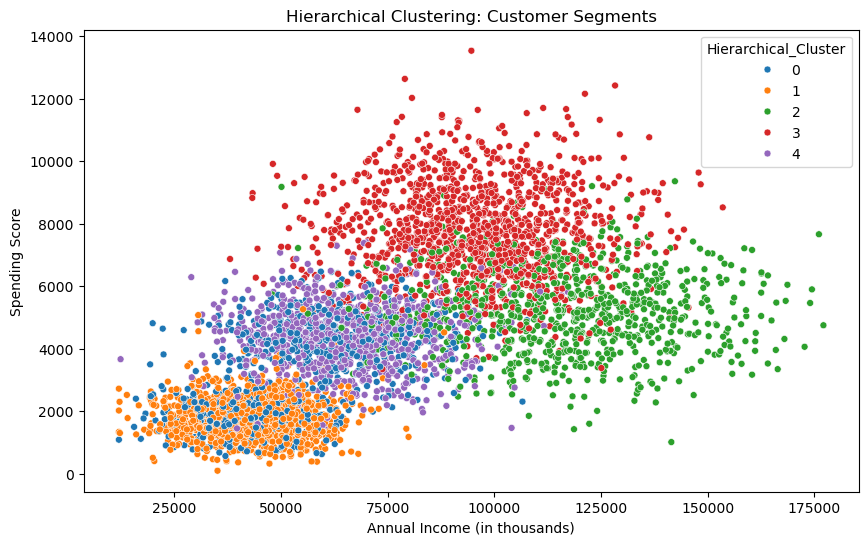

In [30]:
import seaborn as sns
# Plot customer clusters using income and spending score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual_Income_INR'],
    y=df['Monthly_Spend_INR'],
    hue=df['Hierarchical_Cluster'],
    palette='tab10',
    s=25
)

plt.title('Hierarchical Clustering: Customer Segments')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()

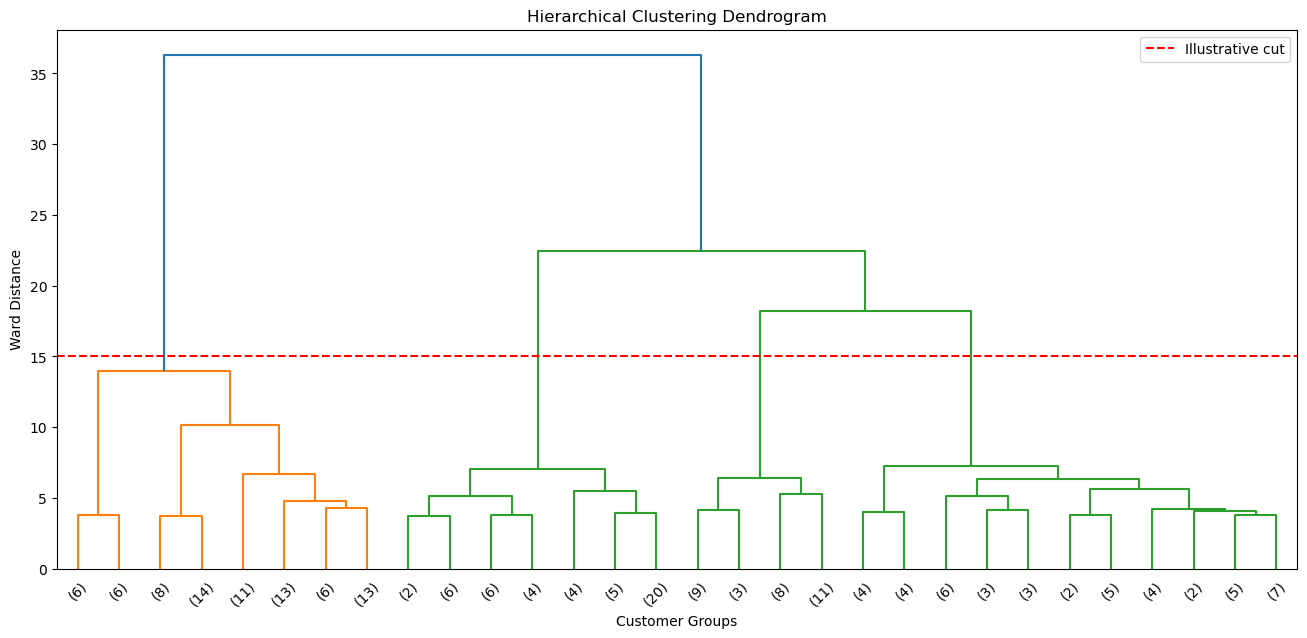

In [33]:

from scipy.cluster.hierarchy import dendrogram, linkage

# Select 200 customers for a readable dendrogram
sample = df.sample(n=200, random_state=42)

# Keep only the numeric columns needed for clustering
X_sample = sample.drop(columns=['Customer_ID', 'Preferred_Category', 'Primary_Channel'])
X_sample_scaled = StandardScaler().fit_transform(X_sample)

# Perform hierarchical clustering using Ward linkage
linked = linkage(X_sample_scaled, method='ward')

# Plot the dendrogram
plt.figure(figsize=(16, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Ward Distance')
plt.axhline(y=15, color='red', linestyle='--', label='Illustrative cut')
plt.legend()
plt.show()


#Evaluate Clusters
* Calculate the Silhouette Score



In [34]:
score = silhouette_score(X_scaled, df['Hierarchical_Cluster'])
                                                              
                                                              
print("Silhouette Score:", round(score, 3))                   

Silhouette Score: 0.244



# DBSCAN

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [36]:
# Create the DBSCAN model
dbscan = DBSCAN(
    eps=0.7,
    min_samples=10
)

# Fit the model and assign cluster labels
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Display the assigned clusters
print(df[['Customer_ID', 'DBSCAN_Cluster']].head(10))

  Customer_ID  DBSCAN_Cluster
0   CUST00001              -1
1   CUST00002              -1
2   CUST00003              -1
3   CUST00004              -1
4   CUST00005              -1
5   CUST00006              -1
6   CUST00007               2
7   CUST00008              -1
8   CUST00009              -1
9   CUST00010              -1


In [37]:

# Count observations in each cluster
print(df['DBSCAN_Cluster'].value_counts().sort_index())

# Count observations identified as noise
noise_count = (df['DBSCAN_Cluster'] == -1).sum()

print("Number of noise points:", noise_count)

# Count the actual clusters, excluding noise
number_of_clusters = len(set(df['DBSCAN_Cluster'])) - (
    1 if -1 in df['DBSCAN_Cluster'] else 0
)

print("Number of clusters:", number_of_clusters)

DBSCAN_Cluster
-1    4115
 0     226
 1     495
 2     121
 3      11
 4      11
 5      11
 6      10
Name: count, dtype: int64
Number of noise points: 4115
Number of clusters: 8


In [40]:
print(X.columns)

Index(['Age', 'Annual_Income_INR', 'Monthly_Spend_INR', 'Monthly_Visits',
       'Orders_Per_Month', 'Discount_Purchase_Ratio', 'Avg_Session_Minutes',
       'Returns_Per_Year', 'Preferred_Category', 'Primary_Channel'],
      dtype='object')


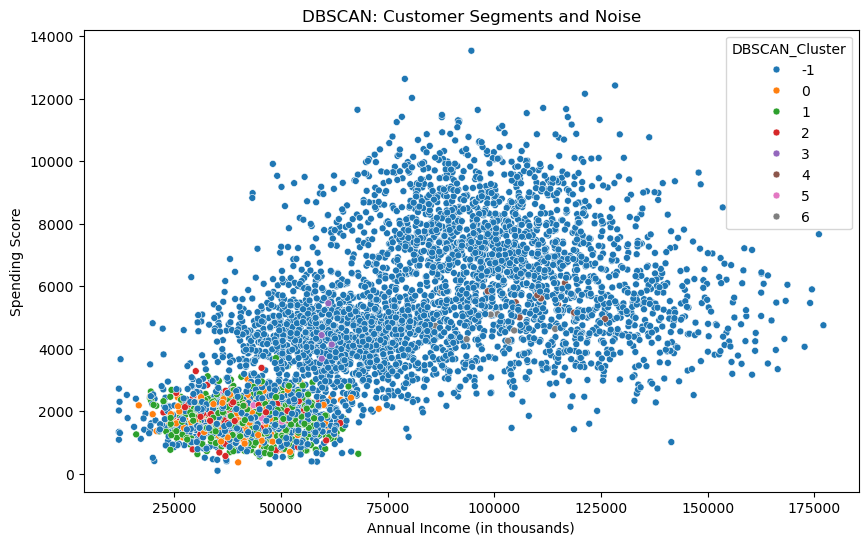

In [41]:

# Visualize clusters using income and spending score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df['Annual_Income_INR'],
    y=df['Monthly_Spend_INR'],
    hue=df['DBSCAN_Cluster'],
    palette='tab10',
    s=25
)

plt.title('DBSCAN: Customer Segments and Noise')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()
     

In [42]:
#Evaluation DBSCAN
# Identify observations that are not noise
mask = df['DBSCAN_Cluster'] != -1

# Get the cluster labels excluding noise
labels = df.loc[mask, 'DBSCAN_Cluster']

# Calculate the score only if there are at least two clusters
if labels.nunique() >= 2 and labels.nunique() < len(labels):

    score = silhouette_score(
        X_scaled[mask],
        labels
    )

    print("Silhouette Score:", round(score, 3))

else:
    print("Silhouette Score cannot be calculated meaningfully.")
    print("Try adjusting eps or min_samples.")

Silhouette Score: 0.233


In [43]:
  #Experiment with DBSCAN parameters
#If DBSCAN identifies only one cluster or labels most observations as noise, try changing eps.
# Try different eps values
for eps_value in [0.5, 0.7, 0.9, 1.1, 1.3]:

    # Create and fit a new DBSCAN model
    model = DBSCAN(
        eps=eps_value,
        min_samples=10
    )

    labels = model.fit_predict(X_scaled)

    # Count clusters, excluding noise
    clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Count noise points
    noise = (labels == -1).sum()

    print(
        "eps:", eps_value,
        "| Clusters:", clusters,
        "| Noise points:", noise
    )

eps: 0.5 | Clusters: 0 | Noise points: 5000
eps: 0.7 | Clusters: 7 | Noise points: 4115
eps: 0.9 | Clusters: 16 | Noise points: 2374
eps: 1.1 | Clusters: 5 | Noise points: 848
eps: 1.3 | Clusters: 3 | Noise points: 221


In [44]:
#Again running DBSCAN with least noise eps
# Create the DBSCAN model
dbscan = DBSCAN(
    eps=0.9,
    min_samples=10
)

# Fit the model and assign cluster labels
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Display the assigned clusters
print(df[['Customer_ID', 'DBSCAN_Cluster']].head(10))
     

  Customer_ID  DBSCAN_Cluster
0   CUST00001               9
1   CUST00002              -1
2   CUST00003              -1
3   CUST00004              -1
4   CUST00005               0
5   CUST00006              -1
6   CUST00007               1
7   CUST00008              -1
8   CUST00009              -1
9   CUST00010               2


# KMEANS

In [45]:
#KMEANS
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
     

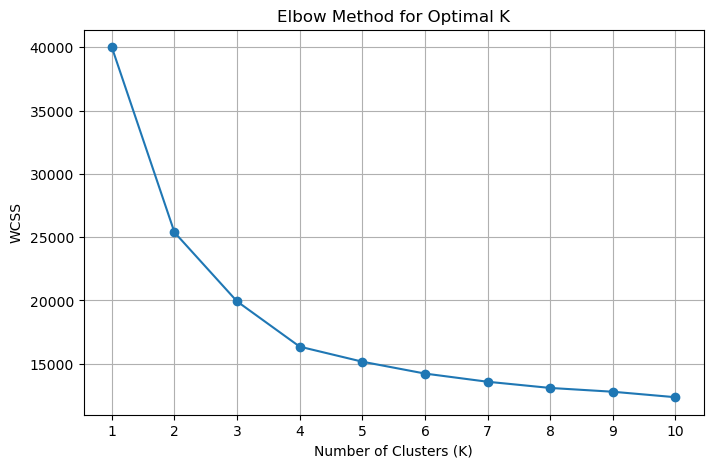

In [46]:
#elbow
# Store the WCSS values for different K values
wcss = []

# Test cluster counts from 1 to 10
for k in range(1, 11):

    # Create the K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model
    kmeans.fit(X_scaled)

    # Store the WCSS value
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [47]:

# Create the final K-Means model
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Fit the model and assign cluster labels
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer IDs and their assigned clusters
print(df[['Customer_ID', 'KMeans_Cluster']].head(10))

  Customer_ID  KMeans_Cluster
0   CUST00001               4
1   CUST00002               2
2   CUST00003               3
3   CUST00004               4
4   CUST00005               3
5   CUST00006               0
6   CUST00007               0
7   CUST00008               3
8   CUST00009               3
9   CUST00010               0


In [48]:
# Count the number of customers in each cluster
print(df['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    1467
1     855
2     561
3     894
4    1223
Name: count, dtype: int64


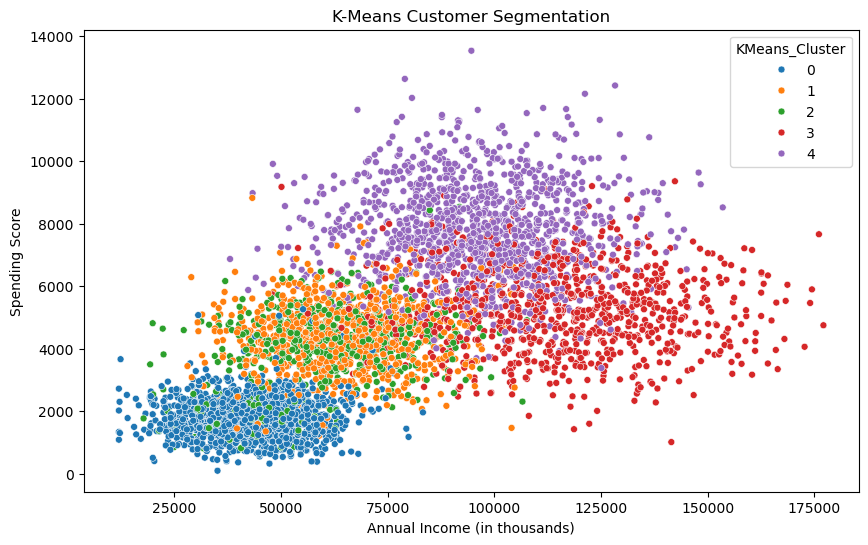

In [51]:

# Create a scatter plot of the customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual_Income_INR',
    y='Monthly_Spend_INR',
    hue='KMeans_Cluster',
    palette='tab10',
    s=25
)

plt.title('K-Means Customer Segmentation')
plt.xlabel('Annual Income (in thousands)')
plt.ylabel('Spending Score')
plt.show()

In [52]:
# Calculate the Silhouette Score
score = silhouette_score(
    X_scaled,
    df['KMeans_Cluster']
)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.26


In [53]:
#TUNING MODELS-
#K-Means: Hyperparameter tuning
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import silhouette_score, make_scorer

# Create a custom Silhouette Score scorer
def silhouette_scorer(estimator, X):
    labels = estimator.fit_predict(X)

    if len(set(labels)) < 2:
        return -1

    return silhouette_score(X, labels)

# Create the model
kmeans = KMeans(random_state=42, n_init=10)

# Define parameters to test
params = {
    'n_clusters': [2, 3, 4, 5, 6, 7, 8, 9, 10]
}

# Run parameter search
grid = GridSearchCV(
    kmeans,
    params,
    scoring=silhouette_scorer,
    cv=3,
    n_jobs=-1
)

grid.fit(X_scaled) 

# Display the best parameters and score
print("Best Parameters:", grid.best_params_)
print("Best Silhouette Score:", grid.best_score_)

# Save the best model
best_kmeans = grid.best_estimator_

# Assign final clusters
df['KMeans_Cluster_Tuned'] = best_kmeans.fit_predict(X_scaled)

Best Parameters: {'n_clusters': 2}
Best Silhouette Score: 0.30859437027409425


In [54]:
#Hierarchical Clustering: Hyperparameter tuning
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import silhouette_score

# Test different parameter combinations
params = {
    'n_clusters': [2, 3, 4, 5, 6, 7, 8],
    'linkage': ['ward', 'complete', 'average']
}

best_score = -1
best_params = None
best_hc = None

# Test each combination on the standardized data
for p in ParameterGrid(params):

    # Ward linkage requires Euclidean distance
    model = AgglomerativeClustering(**p)

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    if score > best_score:
        best_score = score
        best_params = p
        best_hc = model

# Display the best parameters and score
print("Best Parameters:", best_params)
print("Best Silhouette Score:", best_score)

# Assign final clusters using the best parameters
best_hc = AgglomerativeClustering(**best_params)
df['HC_Cluster_Tuned'] = best_hc.fit_predict(X_scaled)

Best Parameters: {'linkage': 'average', 'n_clusters': 2}
Best Silhouette Score: 0.3092798601476639
